# μ → eγ in the soft-broken 3HDM-S₃

**A research notebook, not a tutorial.** It builds on notebook 06 (decays and LFV rates in
the soft-broken vacuum) and asks one question of the same 2028 viable soft points:

> Does $\mu\to e\gamma$ bound the lepton dial $\mu_3^\ell$, the scalar sector, or neither,
> and how much harder than $h\to e\mu$?

Notebook 06 found that $h\to e\mu$ binds hardest among the Higgs LFV decays, yet excludes only
5 of 2028 scalar points. In flavour-violating Higgs models, though, the radiative decay is
usually far stronger than the Higgs decay it is built from [HKZ13]. Here it is computed at
every point, every allowed $\mu_3$ and every lepton branch, and compared with MEG II,
$\mathcal B(\mu^+\to e^+\gamma)<1.5\times10^{-13}$ at 90% CL [MEGII25].

**What is summed** (`radiative.py`, `soft_decays.mu_e_gamma`):

| piece | diagrams | source |
|---|---|---|
| one loop, neutral | $h_{1,2,3}$, $A_{1,2}$ with $\ell_f=e,\mu,\tau$ | [HKZ13] Eq. (A3), exact in $m_f/m_\phi$ |
| one loop, charged | $H^\pm_{1,2}$ with massless ν | [OST16] Eq. (32) |
| Barr–Zee, fermion | $t$, $b$ (**ansatz**), τ (computed) in the $\phi\gamma\gamma$ loop | [OST16] Eq. (20) = [HKZ13] Eq. (A4) |
| Barr–Zee, $W$ | $W$ + Goldstones, $g_{h_iVV}=\kappa_i$ | [OST16] Eq. (20) = [HKZ13] Eq. (A5) |
| Barr–Zee, $H^\pm$ | $H^\pm_{1,2}$ with the $h_iH^+_aH^-_a$ trilinears | built from [Ilisie15] Eqs. (11), (13) |

The quark couplings are an **ansatz**: each quark's Yukawa lies along the vacuum direction,
so $y_{tt}(h_i)=\kappa_i m_t/v$ and the CP-odd states have none. This is the same stand-in for
the missing per-point quark sector that notebook 06 used for $R_{\gamma\gamma}$. The
$\phi Z\gamma$ Barr–Zee pieces (suppressed by $1-4s_W^2$), the $H^\pm W^\mp\gamma$ pieces and
[HKZ13]'s "set C" are not included (§2.4 sizes the first).

Every step uses the four moves of `derive.py` (set up → collect → recognise → check). §1
derives the couplings and §2 the amplitude, each checked against an independent source. §3
and §4 are the exact-S₃ limit and the S₃ image. §5 is the scan and §6 the deliverable.

In [ ]:
import json, logging, math, sys, time
from pathlib import Path

import numpy as np
import sympy as sp
import matplotlib
logging.getLogger("matplotlib").setLevel(logging.CRITICAL)  # a broken personal
import matplotlib.pyplot as plt                             # stylelib file is noisy
from scipy.integrate import quad

sys.path.insert(0, str(Path.cwd()))
import store                             # per-point data in cache/, summaries in results/
import soft_decays as S
import lfv
import decays as D
import radiative as RD
from model import V_EW
from sm_inputs import ALPHA, G_F, M_W, M_Z, M_T, GAMMA_H_SM, M_H as MH_REF
import derive as dv

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
sp.init_printing(use_latex="mathjax")
ok = dv.ok
C_BLUE, C_RED, C_GREEN, C_GREY = "#4C72B0", "#C44E52", "#55A868", "#8C8C8C"


def check_quoted(section, rows):
    "Assert that the numbers the markdown quotes still match this run."
    stale = [(what, got, want) for what, got, want, tol in rows if abs(float(got) - float(want)) > tol]
    assert not stale, "§%s prose is stale (what, computed, quoted): %s" % (section, stale)
    ok("the %d numbers quoted in §%s match this run" % (len(rows), section))


ledger = dv.Ledger("07 — the radiative decay of the muon in the soft-broken vacuum")
ME, MMU, MTAU = lfv.LEPTON_MASSES
MEG = S.MEG_II_LIMIT
LIMIT_EMU = D.LFV_LIMITS[("e", "mu")]                 # [CMS23], B(h -> e mu) < 4.4e-5
LIMIT = {f"{a}{b}": lim for (a, b), lim in D.LFV_LIMITS.items()}
PAIRS = {"taumu": (2, 1), "taue": (2, 0), "emu": (0, 1)}

t0 = time.time()
T = S.build_tools()
points = store.points("viable_points_soft")
grid = np.linspace(-0.9995 * MTAU, 0.9995 * MTAU, 73)   # notebook 06's mu_3 grid
print("soft model + lambdified tools built in %.1f s; %d viable soft points" % (time.time() - t0, len(points)))
print("MEG II limit %.1e, h -> e mu limit %.1e" % (MEG, LIMIT_EMU))

soft model + lambdified tools built in 3.2 s; 2028 viable soft points
MEG II limit 1.5e-13, h -> e mu limit 4.4e-05


---
## 1. Every scalar's lepton couplings, read off the Lagrangian

h→ℓℓ′ needed only the CP-even couplings. μ→eγ also needs the CP-odd and charged ones, and the
**sign** of each lepton mass, because the τ-enhanced term $m_\tau Y^*_{\tau e}Y^*_{\mu\tau}$
changes sign with the τ eigenvalue.

**Set up.** `lfv.scalar_lepton_couplings` expands each doublet as
$H_k=\big(c_k,\ (v_k+r_k+i a_k)/\sqrt2\big)$ inside the five-term Yukawa Lagrangian and
differentiates the coefficient of each sandwich with respect to each component. This gives
$L\supset-\bar e_L Y^{(r_k)} e_R\,r_k-\bar e_L Y^{(a_k)}e_R\,a_k-\bar\nu_L Y^{(c_k)}e_R\,c_k+\text{h.c.}$,
the convention of [OST16] Eq. (6). Nothing is typed in: that is the lesson of notebook 03's
$G_2=0$ split.

> **Predict.** How are $Y^{(a_k)}$ and $Y^{(c_k)}$ related to $Y^{(r_k)}$? (The Yukawas are
> $\bar L H e_R$, with $H$ un-conjugated.)

In [ ]:
rng = np.random.default_rng(7)
Y_test = rng.normal(size=5)
C = T.yuk_of(Y_test)
G = T.g_of(Y_test)
for name in ("even", "odd", "charged"):
    print(name, "doublet 1 block:")
    print(np.array2string(C[name][0], precision=4, suppress_small=True))
dev = {"even = G_k (notebook 03/06)": max(np.abs(C["even"][k] - G[k]).max() for k in range(3)),
       "odd = i even": max(np.abs(C["odd"][k] - 1j * C["even"][k]).max() for k in range(3)),
       "charged = sqrt2 even": max(np.abs(C["charged"][k] - math.sqrt(2) * C["even"][k]).max() for k in range(3))}
for k_, v_ in dev.items():
    print("  max |%s| residual: %.1e" % (k_, v_))
assert max(dev.values()) < 1e-15
ok("Y(a_k) = i Y(r_k) and Y(c_k) = sqrt2 Y(r_k), for every doublet k")
dv.falsify("the charged coupling without its sqrt2",
           lambda: max(np.abs(C["charged"][k] - C["even"][k]).max() for k in range(3)) < 1e-15)

even doublet 1 block:
[[ 0.2112  0.     -0.3215]
 [ 0.     -0.2112  0.    ]
 [-0.6297  0.      0.    ]]
odd doublet 1 block:
[[ 0.+0.2112j  0.+0.j     -0.-0.3215j]
 [ 0.+0.j     -0.-0.2112j  0.+0.j    ]
 [-0.-0.6297j  0.+0.j      0.+0.j    ]]
charged doublet 1 block:
[[ 0.2987  0.     -0.4547]
 [ 0.     -0.2987  0.    ]
 [-0.8906  0.      0.    ]]
  max |even = G_k (notebook 03/06)| residual: 0.0e+00
  max |odd = i even| residual: 0.0e+00
  max |charged = sqrt2 even| residual: 1.1e-16
✓ Y(a_k) = i Y(r_k) and Y(c_k) = sqrt2 Y(r_k), for every doublet k
✓ the charged coupling without its sqrt2 — the check fires on a broken input, so it has teeth


True

**Recognise.** Both relations are the doublet structure and nothing more. $H^0$ enters the
Yukawa linearly as $(v+r+ia)/\sqrt2$, so $\partial_a=i\,\partial_r$. The charged component
is a canonically normalized complex field without the $1/\sqrt2$, so it carries $\sqrt2$
times the real neutral field's coupling. In the mass basis
$Y^{\phi}=O^{\mathsf T}\big(\sum_k R_{k\phi}Y^{(k)}\big)O\,\mathrm{diag}(s)$, where the
columns of $R$ are the physical states (`R_even`, `R_odd`, `R_C`) and $s$ are the signs of
the eigenvalues of $M_\ell$ (`lfv.signed_mass_basis`).

**Check 1: the Goldstones carry no flavour violation.** Their columns are the vacuum
direction $\hat v$, and $\sum_k\hat v_kY^{(r_k)}=M_\ell/v$ is diagonal in the mass basis at
*any* vacuum (notebook 06 §5). So $Y^{G^0}=i\,\mathrm{diag}(m)/v$ and
$Y^{G^+}=\sqrt2\,\mathrm{diag}(m)/v$, after the sign rephasing. This is what licenses
leaving them out of `mu_e_gamma`.

In [ ]:
t0 = time.time()
rots = [S.point_rotations(T, p) for p in points]
print("rebuilt %d points in %.1f s" % (len(rots), time.time() - t0))

worst_g = 0.0
for r in rots[::20]:
    v = np.linalg.norm(r["vevs"])
    for br in lfv.lepton_branches(T.g_of, grid[-1], r["vevs"]) + lfv.lepton_branches(T.g_of, 0.3, r["vevs"]):
        masses, Yp = S.mass_basis_yukawas(T, br["Y"], r)
        sg0 = np.sign((Yp["G0"] / 1j).real[0, 0] or 1.0)       # the Goldstone column's sign is a convention
        sgp = np.sign(Yp["Gp"][0, 0] or 1.0)
        worst_g = max(worst_g, np.abs(sg0 * Yp["G0"] - 1j * np.diag(masses) / v).max() * v / MTAU,
                      np.abs(sgp * Yp["Gp"] - math.sqrt(2) * np.diag(masses) / v).max() * v / MTAU)
print("max deviation from i diag(m)/v and sqrt2 diag(m)/v, in units of m_tau/v: %.1e" % worst_g)
assert worst_g < 1e-12
ok("the Goldstone lepton couplings are flavour-diagonal and fixed by the masses at every soft vacuum")

rebuilt 2028 points in 0.4 s


max deviation from i diag(m)/v and sqrt2 diag(m)/v, in units of m_tau/v: 1.9e-15
✓ the Goldstone lepton couplings are flavour-diagonal and fixed by the masses at every soft vacuum


**Check 2: against feynlag's own extractor.** At a genuinely non-aligned point, build the
full model with the point's rotations and register the lepton mass basis
(`decays.build_decay_model`, `decays.register_lepton_basis`). Then run
`extract_fermion_vertices` on the physical Yukawa Lagrangian and compare every $h_i$, $A_a$
and $H^+_a$ coupling with the matrices above. This is an independent route: rotations
registered on a `Model`, `physical_lagrangian`, and the bilinear extractor. The extractor
has no sign rephasing, so the comparison is made before $\mathrm{diag}(s)$, and the
neutrinos stay in the weak basis (their legs are not rotated).

In [ ]:
from feynlag.vertices.bilinear import extract_fermion_vertices

p0, r0 = points[0], rots[0]
br0 = lfv.lepton_branches(T.g_of, grid[-1], r0["vevs"])[0]
C0 = T.yuk_of(br0["Y"])
masses0, O0, s0 = lfv.signed_mass_basis(C0["even"], r0["vevs"])
print("point 0: phi = %.2f deg (alignment is 60), lepton branch kind %r, eigenvalue signs %s"
      % (math.degrees(p0["phi"]), br0["kind"], s0))

t0 = time.time()
dm = D.build_decay_model(scalar=T.model, rotations=(r0["R_even"], r0["R_odd"], r0["R_C"]))
phys_L, phys_R, phys_Lbar, phys_Rbar = D.register_lepton_basis(dm, sp.Matrix(O0))
num = dict(zip(dm.lepton.coupling_symbols, br0["Y"]))
num.update(dict(zip((T.model.v1.s, T.model.v2.s, T.model.vS.s), r0["vevs"])))
Lyuk = sp.expand(dm.model.physical_lagrangian(sector="yukawa").xreplace({k: sp.Float(v) for k, v in num.items()}))
ffs = extract_fermion_vertices(Lyuk, list(dm.cp_even) + list(dm.cp_odd) + list(dm.charged) + list(dm.negative))
print("extracted %d fermion-bilinear keys in %.1f s" % (len(ffs), time.time() - t0))

nu_bars = [f.bar_components[0][0] for f in dm.lepton.left]


PR = next(k[1] for k in ffs)                          # the P_R chirality structure of every key
worst = {}
for col, sym in enumerate(dm.cp_even):                 # columns of R_even <-> (h_1, h_0, h_2)
    mine = O0.T @ sum(r0["R_even"][k, col] * C0["even"][k] for k in range(3)) @ O0
    got = np.array([[-complex(sp.N(ffs.get((phys_Lbar[i], PR, phys_R[j]), {}).get(1, {}).get((sym,), 0)))
                     for j in range(3)] for i in range(3)])
    worst["CP-even"] = max(worst.get("CP-even", 0), np.abs(got - mine).max())
for col in (1, 2):
    sym = dm.cp_odd[col]
    mine = O0.T @ sum(r0["R_odd"][k, col] * C0["odd"][k] for k in range(3)) @ O0
    got = np.array([[-complex(sp.N(ffs.get((phys_Lbar[i], PR, phys_R[j]), {}).get(1, {}).get((sym,), 0)))
                     for j in range(3)] for i in range(3)])
    worst["CP-odd"] = max(worst.get("CP-odd", 0), np.abs(got - mine).max())
for col in (1, 2):
    sym = dm.charged[col]
    mine = sum(r0["R_C"][k, col] * C0["charged"][k] for k in range(3)) @ O0
    got = np.array([[-complex(sp.N(ffs.get((nu_bars[i], PR, phys_R[j]), {}).get(1, {}).get((sym,), 0)))
                     for j in range(3)] for i in range(3)])
    worst["charged"] = max(worst.get("charged", 0), np.abs(got - mine).max())
    assert np.abs(mine).max() > 1e-4, "a vacuous comparison"
for k_, v_ in worst.items():
    print("  max |extractor - lfv.scalar_lepton_couplings|, %-8s %.1e" % (k_ + ":", v_))
assert max(worst.values()) < 1e-15
ok("all 7 physical scalars' lepton couplings agree with feynlag's extractor at a non-aligned point")

point 0: phi = 13.26 deg (alignment is 60), lepton branch kind 'mu', eigenvalue signs [1. 1. 1.]


extracted 36 fermion-bilinear keys in 1.4 s
  max |extractor - lfv.scalar_lepton_couplings|, CP-even: 1.7e-18
  max |extractor - lfv.scalar_lepton_couplings|, CP-odd:  1.7e-18
  max |extractor - lfv.scalar_lepton_couplings|, charged: 1.1e-19
✓ all 7 physical scalars' lepton couplings agree with feynlag's extractor at a non-aligned point


---
## 2. The amplitude, checked piece by piece

$T=e\,\varepsilon^*_\alpha\,\bar u_e\,m_\mu i\sigma^{\alpha\beta}q_\beta\,(A_LP_L+A_RP_R)\,u_\mu$
and $\mathcal B(\mu\to e\gamma)=48\pi^3\alpha\,(|A_L|^2+|A_R|^2)/G_F^2$ ([OST16] Eqs. (28)–(29)).
[HKZ13]'s Wilson coefficients are $c=4\pi^2A$: their rate, Eq. (15), against the line above
fixes $|c|=4\pi^2|A|$, and their one-loop Eq. (13) equals [OST16] Eq. (19) term by term,
sign included. Both papers then quote the **same** Barr–Zee formulae, so the one-loop and
two-loop pieces can be added with a common sign.

### 2.1 One loop, neutral scalars: the Feynman-parameter integral in closed form

**Set up.** [HKZ13] Eq. (A3) for $\mu\to e\gamma$ (i = μ decays, j = e) is

$$c_L=\sum_f\frac{1}{4m_\mu}\int dx\,dy\,dz\,\delta(1-x-y-z)\,
\frac{xz\,m_eY_{ef}Y^*_{\mu f}+yz\,m_\mu Y^*_{fe}Y_{f\mu}+(x+y)\,m_fY^*_{fe}Y^*_{\mu f}}
{z m_\phi^2-xz\,m_e^2-yz\,m_\mu^2+(x+y)\,m_f^2},$$

with $c_R$ obtained by $Y\to Y^\dagger$. Drop the external masses from the denominator
($m_\mu^2/m_\phi^2\lesssim10^{-6}$). The denominator then depends on $z$ alone, the $x$, $y$
integrals are elementary ($\int_0^{1-z}x\,dx=(1-z)^2/2$), and two functions of
$t=m_f^2/m_\phi^2$ are left:
$c_L=\sum_f\big[\tfrac12 I_1(t_f)(m_eY_{ef}Y^*_{\mu f}+m_\mu Y^*_{fe}Y_{f\mu})+I_2(t_f)\,m_fY^*_{fe}Y^*_{\mu f}\big]/(4m_\mu m_\phi^2)$.

In [ ]:
z_, t_ = sp.symbols("z t", positive=True)
Dz = z_ + (1 - z_) * t_
I1_s = sp.simplify(sp.integrate(sp.apart(z_ * (1 - z_) ** 2 / Dz, z_), (z_, 0, 1)))
I2_s = sp.simplify(sp.integrate(sp.apart((1 - z_) ** 2 / Dz, z_), (z_, 0, 1)))
dv.show("I_1(t) = int z(1-z)^2/(z+(1-z)t) dz =", I1_s, count_terms=False)
dv.show("I_2(t) = int (1-z)^2/(z+(1-z)t) dz =", I2_s, count_terms=False)

# the closed forms coded in radiative.py are these
# (exact values at 30 digits: in double precision the closed forms cancel as (1 - t)^4 near t = 1,
#  which is why radiative.py switches to quadrature within 0.05 of it)
worst_I = 0.0
for tv in (1e-9, 3e-4, 0.2, 0.96, 0.999, 1.0004, 1.06, 7.0):
    for fn, ex in ((RD.I1, I1_s), (RD.I2, I2_s)):
        exact = float(ex.subs(t_, sp.Float(tv, 40)).evalf(30))
        worst_I = max(worst_I, abs(fn(tv) / exact - 1))
print("max relative error of radiative.I1/I2 against the 30-digit closed forms: %.1e" % worst_I)
assert worst_I < 1e-9
ok("radiative.I1/I2 are the derived closed forms, including next to t = 1")

# recognise: the light-fermion limits
eps = sp.Symbol("epsilon", positive=True)
lim2 = sp.limit(I2_s.subs(t_, eps) + sp.log(eps), eps, 0)
lim1 = sp.limit(I1_s.subs(t_, eps), eps, 0)
print("t -> 0:  I_2 + log t ->", lim2, ";  I_1 ->", lim1)
assert lim2 == sp.Rational(-3, 2) and lim1 == sp.Rational(1, 3)
ok("I_2 -> log(m_phi^2/m_f^2) - 3/2 and I_1 -> 1/3: the [OST16] Eq. (30) / [HKZ13] Eq. (16) logs")

I_1(t) = int z(1-z)^2/(z+(1-z)t) dz =


 3                        
t     2              t   1
── - t  + t⋅log(t) + ─ + ─
6                    2   3
──────────────────────────
 4      3      2          
t  - 4⋅t  + 6⋅t  - 4⋅t + 1

I_2(t) = int (1-z)^2/(z+(1-z)t) dz =


 2                     
t  - 4⋅t + 2⋅log(t) + 3
───────────────────────
  ⎛ 3      2          ⎞
2⋅⎝t  - 3⋅t  + 3⋅t - 1⎠

max relative error of radiative.I1/I2 against the 30-digit closed forms: 6.0e-11
✓ radiative.I1/I2 are the derived closed forms, including next to t = 1
t -> 0:  I_2 + log t -> -3/2 ;  I_1 -> 1/3
✓ I_2 -> log(m_phi^2/m_f^2) - 3/2 and I_1 -> 1/3: the [OST16] Eq. (30) / [HKZ13] Eq. (16) logs


**Recognise.** $I_2\to\log(m_\phi^2/m_f^2)-\tfrac32$ is the chirality-flip log of [OST16]
Eq. (30). With $I_1\to\tfrac13$ the non-flip term becomes
$Y^*_{fe}Y_{f\mu}/(96\pi^2m_\phi^2)$, which is [OST16]'s $y_{i\mu}/6$ piece, **but without
the factor $m_i/m_\mu$** that Eq. (30) attaches to it. That factor cannot be right. The
non-flip term takes its chirality flip from the *external* muon, so it carries $m_\mu$,
which the $1/m_\mu$ prefactor cancels. Both [HKZ13] Eq. (A3) above and [OST16]'s own τ→μγ
Eq. (19), where the decaying lepton and the internal one coincide, agree with this.
`radiative.py` follows (A3).

**Check: the closed form against the full two-parameter integral.** Below, Eq. (A3) is
integrated numerically with the external masses **kept**, at a heavy and a light scalar,
for random complex Yukawas. The two routes share nothing but the integrand's definition.

In [ ]:
def hkz_c(Y, masses, m_phi, left=True):
    "[HKZ13] Eq. (A3) summed over f, by direct 2D quadrature, external masses kept."
    Y = Y if left else Y.conj().T
    mi, mj = masses[1], masses[0]
    tot = 0j
    for f in range(3):
        mf = masses[f]
        nums = (mj * Y[0, f] * np.conj(Y[1, f]), mi * np.conj(Y[f, 0]) * Y[f, 1], mf * np.conj(Y[f, 0]) * np.conj(Y[1, f]))
        for part, wfun in zip(nums, (lambda x, z: x * z, lambda x, z: (1 - z - x) * z, lambda x, z: 1 - z)):
            def inner(z):
                den = lambda x: (z * m_phi**2 - x * z * mj**2 - (1 - z - x) * z * mi**2 + (1 - z) * mf**2)
                return quad(lambda x: wfun(x, z) / den(x), 0, 1 - z, epsrel=1e-11)[0]
            val = quad(inner, 0, 1, points=[1e-10, 1e-8, 1e-6, 1e-4, 1e-2], limit=400, epsrel=1e-10)[0]
            tot += part * val
    return tot / (4 * mi)

masses_t = np.array(lfv.LEPTON_MASSES)
Yr = (rng.normal(size=(3, 3)) + 1j * rng.normal(size=(3, 3))) * 1e-3
worst_rel = 0.0
for m_phi in (700.0, 25.0):
    AL, AR = RD.one_loop_neutral(Yr, masses_t, m_phi)
    cL, cR = hkz_c(Yr, masses_t, m_phi), hkz_c(Yr, masses_t, m_phi, left=False)
    rel = max(abs(4 * math.pi**2 * AL / cL - 1), abs(4 * math.pi**2 * AR / cR - 1))
    worst_rel = max(worst_rel, rel)
    print("m_phi = %5.0f GeV: |4pi^2 A / c_HKZ - 1| = %.1e  (external-mass terms ~ m_mu^2/m_phi^2 = %.0e)"
          % (m_phi, rel, MMU**2 / m_phi**2))
assert worst_rel < 1e-4
ok("closed-form one loop = [HKZ13] Eq. (A3) with the external masses kept, at a heavy and a light scalar")
dv.falsify("the closed form with [OST16]'s m_i/m_mu on the non-flip term",
           lambda: abs(4 * math.pi**2 * (RD.one_loop_neutral(Yr, masses_t, 700.0)[0]
                                         + sum(np.conj(Yr[f, 0]) * Yr[f, 1] * (masses_t[f] / MMU - 1) * RD.I1(masses_t[f]**2 / 700**2)
                                               / (8 * MMU * 700**2) * MMU / (4 * math.pi**2) for f in range(3)))
                       / hkz_c(Yr, masses_t, 700.0) - 1) < 1e-4)

m_phi =   700 GeV: |4pi^2 A / c_HKZ - 1| = 1.1e-08  (external-mass terms ~ m_mu^2/m_phi^2 = 2e-08)
m_phi =    25 GeV: |4pi^2 A / c_HKZ - 1| = 6.3e-06  (external-mass terms ~ m_mu^2/m_phi^2 = 2e-05)
✓ closed-form one loop = [HKZ13] Eq. (A3) with the external masses kept, at a heavy and a light scalar
✓ the closed form with [OST16]'s m_i/m_mu on the non-flip term — the check fires on a broken input, so it has teeth


True

### 2.2 One loop, charged scalars

With massless neutrinos only the non-flip structure survives, and [OST16] Eq. (32) gives
$A_L=-(Y_C^\dagger Y_C)_{e\mu}/(192\pi^2m_{H^\pm}^2)$, $A_R=0$.

> **Predict.** Relative to the neutral non-flip term $Y^*Y/(96\pi^2m_\phi^2)$ that is a factor
> $-\tfrac12$. Where do the sign and the ½ come from?

**Check, from a third source.** [Lavoura03] writes every scalar loop as one formula with the
photon on the internal fermion (charge $Q_F$) or on the internal boson ($Q_B$). Its
non-flip coefficients in the $m_{1,2}\to0$ limit are Eq. (40), $(c+d)$, for the photon on
the fermion and Eq. (41), $(-\bar c+\bar d)$, for the photon on the scalar. The neutral
loop has $Q_F=-1$, $Q_B=0$. The charged loop has $Q_F=0$ (ν) and $Q_B=+1$, since in
$B\bar Ff$ the boson's charge is $Q_F-Q_f$.

In [ ]:
tl = sp.Symbol("t", positive=True)
lav40 = (tl**2 - 5 * tl - 2) / (12 * (tl - 1) ** 3) + tl * sp.log(tl) / (2 * (tl - 1) ** 4)      # [Lavoura03] (40)
lav41 = (2 * tl**2 + 5 * tl - 1) / (12 * (tl - 1) ** 3) - tl**2 * sp.log(tl) / (2 * (tl - 1) ** 4)  # [Lavoura03] (41)
neutral = -1 * sp.limit(lav40, tl, 0)        # Q_F = -1, internal charged lepton (light: t -> 0)
charged = +1 * sp.limit(lav41, tl, 0)        # Q_B = +1, internal neutrino (massless: t = 0)
ratio_lav = sp.nsimplify(charged / neutral)
ratio_ost = sp.Rational(-1, 192) / sp.Rational(1, 96)
print("[Lavoura03] charged/neutral non-flip at t -> 0:", ratio_lav, "  [OST16] (32) vs the I_1 -> 1/3 term:", ratio_ost)
assert ratio_lav == ratio_ost == sp.Rational(-1, 2)
ok("the charged loop is -1/2 the neutral non-flip loop, from [Lavoura03] and [OST16] independently")

# and radiative.one_loop_charged is that formula
Yc = rng.normal(size=(3, 3)) * 1e-3
assert abs(RD.one_loop_charged(Yc, 400.0)[0] + (Yc.T @ Yc)[0, 1] / (192 * math.pi**2 * 400.0**2)) < 1e-22
ok("radiative.one_loop_charged is [OST16] Eq. (32)")

[Lavoura03] charged/neutral non-flip at t -> 0: -1/2   [OST16] (32) vs the I_1 -> 1/3 term: -1/2
✓ the charged loop is -1/2 the neutral non-flip loop, from [Lavoura03] and [OST16] independently
✓ radiative.one_loop_charged is [OST16] Eq. (32)


**Recognise.** The ½ is the ratio of the two Feynman-parameter weights at $t=0$ (1/12
against 1/6). The sign is charge conservation: the photon couples to the scalar line with
the opposite sign to the fermion line it replaces.

### 2.3 Barr–Zee: the fermion and $W$ loops against the literature

The [HKZ13] numbers are for τ→μγ through an SM Higgs at $m_h=125$ GeV, with
$\bar m_t=164$ GeV. Their Eq. (14) quotes
$c^{2\text{-loop}}_L=Y^*_{\tau\mu}(-0.082\,Y_{tt}+0.11)/(125\text{ GeV})^2$.

In [ ]:
mt_bar, mh = 164.0, 125.0
bz = RD.barr_zee(1.0, 0.0, mh, ALPHA, 246.0, m_w=M_W, kappa_w=1.0, fermions=[(3, 2 / 3, mt_bar, 1.0)], m_mu=MTAU)
c_top = (4 * math.pi**2 * bz["fermion"][0] * mh**2).real
c_w = (4 * math.pi**2 * bz["W"][0] * mh**2).real
print("top: %.4f per unit Y_tt   ([HKZ13] Eq. (14): -0.082)" % c_top)
print("W:   %.4f                 ([HKZ13] Eq. (14):  0.11)" % c_w)
assert abs(c_top / -0.082 - 1) < 0.02
ok("the top Barr-Zee term reproduces [HKZ13]'s number to %.0f%%" % (100 * abs(c_top / -0.082 - 1)))

top: -0.0811 per unit Y_tt   ([HKZ13] Eq. (14): -0.082)
W:   0.1254                 ([HKZ13] Eq. (14):  0.11)
✓ the top Barr-Zee term reproduces [HKZ13]'s number to 1%


The top term agrees to 1%, but the $W$ term comes out 14% above [HKZ13]'s 0.11. The coded $W$
bracket is [OST16] Eq. (20), lines 3–4, which is identical term by term to [HKZ13] Eq. (A5).
So the disagreement is with the *number*, not the formula. Two further checks locate it.

- **A third source.** [Ilisie15] computes the same $W$-loop Barr–Zee diagrams for $(g-2)_\mu$.
  The flavour-diagonal limit of the dipole gives $\Delta a_\mu=2m_\mu^2A$ (the top term maps
  this way exactly). Matching his Eq. (21) to [OST16]'s normalization then requires the
  bracket to equal his $F^{(3)}(m_W^2/m_\phi^2)$, Eq. (28).
- **The neglected $\phi Z\gamma$ pieces**, [OST16] Eq. (20), lines 5–6.

In [ ]:
def F3_ilisie(w):
    "[Ilisie15] Eq. (28)."
    f = lambda x: (x * (3 * x * (4 * x - 1) + 10) * w - x * (1 - x)) / (w - x * (1 - x)) * math.log(w / (x * (1 - x)))
    s = math.sqrt(max(1 - 4 * w, 0))
    return 0.5 * quad(f, 0, 1, points=[(1 - s) / 2, (1 + s) / 2] if w < 0.25 else None, limit=200)[0]


rows_w = []
for m_phi in (125.0, 300.0, 800.0):
    a, b = RD.w_loop(m_phi, M_W), F3_ilisie(M_W**2 / m_phi**2)
    rows_w.append(abs(a / b - 1))
    print("m_phi = %4.0f GeV: [OST16] W bracket %.4f, [Ilisie15] F3 %.4f, ratio - 1 = %+.1e" % (m_phi, a, b, a / b - 1))
assert max(rows_w) < 0.015
ok("the W bracket agrees with [Ilisie15]'s independent F3 to %.1f%%" % (100 * max(rows_w)))

sw2 = 1 - (M_W / M_Z) ** 2
tw2 = sw2 / (1 - sw2)
xW, xWZ = M_W**2 / mh**2, M_W**2 / M_Z**2
Ft = lambda Fn, x, y: (x * Fn(y) - y * Fn(x)) / (x - y)                    # [OST16] (25)-(26)
brZ = (1 - 4 * sw2) / (8 * sw2) * ((5 - tw2 + (1 - tw2) / (2 * xW)) * Ft(RD.FH, xW, xWZ)
                                   + (7 - 3 * tw2 - (1 - tw2) / (2 * xW)) * Ft(RD.FA, xW, xWZ)
                                   + 1.5 * (RD.FA(xW) + RD.GW(xW)))
zg_share = brZ / RD.w_loop(mh, M_W)
print("phi Z gamma W-loop piece / phi gamma gamma W-loop piece at m_h = 125: %+.3f" % zg_share)

m_phi =  125 GeV: [OST16] W bracket 6.0406, [Ilisie15] F3 5.9777, ratio - 1 = +1.1e-02
m_phi =  300 GeV: [OST16] W bracket 2.2274, [Ilisie15] F3 2.2033, ratio - 1 = +1.1e-02
m_phi =  800 GeV: [OST16] W bracket -0.4529, [Ilisie15] F3 -0.4544, ratio - 1 = -3.3e-03
✓ the W bracket agrees with [Ilisie15]'s independent F3 to 1.1%
phi Z gamma W-loop piece / phi gamma gamma W-loop piece at m_h = 125: +0.060


The $W$ bracket matches [Ilisie15] to about 1%. The $\phi Z\gamma$ piece is a +6% correction,
so it moves *away* from 0.11. The remaining gap is therefore most likely [HKZ13]'s "set C"
diagrams, which their Eq. (14) includes (§A.2: "obtained from [36] by multiplying their
Eq. (20) by −κ") and which are not implemented here. Recorded as an open item. Its effect
on what follows is bounded: §5's conclusions are statements about orders of magnitude.

### 2.4 Barr–Zee: the charged-scalar loop, and its sign

Neither [OST16] nor [HKZ13] has the $H^\pm$ loop in the $\phi\gamma\gamma$ vertex.
[Ilisie15] Eqs. (11) and (13) give the two one-loop $\phi\gamma\gamma$ vertices with an
off-shell photon of momentum $k$:

$$S^{(1)}\propto \frac{m_f^2}{v}N_cQ^2y_f\int dx\,\frac{2x(1-x)-1}{k^2x(1-x)-m_f^2},\qquad
S^{(2)}\propto \frac{v}{2}\lambda\int dx\,\frac{x(x-1)}{k^2x(1-x)-M^2}.$$

Both have the same $k^2$-dependence, so the second loop is the same integral. The $H^\pm$
term is therefore the fermion term of [OST16] Eq. (20) under
$m_f y_{ff}N_cQ^2\,(1-2x(1-x))\to(v\lambda/2)\,x(1-x)$, $m_f\to M_{H^\pm}$. That gives
`radiative.FS` and the `charged` branch of `radiative.barr_zee`.

**The sign of λ is not assumed.** feynlag's trilinear is the Lagrangian coefficient
$L\supset g\,\phi H^+H^-$. If [Ilisie15]'s λ is defined by $L\supset-v\lambda\,\phi H^+H^-$
then $\lambda=-g/v$. The test is the low-energy theorem. With heavy loop particles and a
light $\phi$, the ratio of the scalar to the top contribution must be the same in
[Ilisie15]'s vertices at $k^2=0$ and in feynlag's `higgs_diphoton_amplitude`, whose relative
sign was fixed against [ChakrabartyEtAl21] (`feynlag.pheno.loop.A_zero`).

In [ ]:
from feynlag.pheno.loop import higgs_diphoton_amplitude

M_heavy, m_light, g_test, v = 3000.0, 1.0, 400.0, 246.0
y_t = 1.0                                          # top coupling in SM units (c_t = 1)
# [Ilisie15] (11), (13) at k^2 = 0: the vertex strengths, common factor alpha/pi dropped
S1 = (M_heavy**2 / v) * 3 * (2 / 3) ** 2 * y_t * quad(lambda x: (2 * x * (1 - x) - 1) / (-M_heavy**2), 0, 1)[0]


def S2(lam):
    return (v / 2) * lam * quad(lambda x: x * (x - 1) / (-M_heavy**2), 0, 1)[0]


ratio_feynlag = (higgs_diphoton_amplitude(m_light, [(g_test * v / (2 * M_heavy**2), 0, M_heavy, 1, 1)])
                 / higgs_diphoton_amplitude(m_light, [(y_t, 0.5, M_heavy, 2 / 3, 3)])).real


def lam_sign_check(lam):
    return abs(S2(lam) / S1 / ratio_feynlag - 1) < 1e-4


print("scalar/top, heavy-loop limit: feynlag %.6f, [Ilisie15] with lambda = -g/v: %.6f"
      % (ratio_feynlag, S2(-g_test / v) / S1))
assert lam_sign_check(-g_test / v)
ok("lambda = -g/v: the H+- Barr-Zee term has the sign the low-energy theorem fixes")
dv.falsify("lambda = +g/v", lambda: lam_sign_check(+g_test / v))

scalar/top, heavy-loop limit: feynlag -0.001025, [Ilisie15] with lambda = -g/v: -0.001025
✓ lambda = -g/v: the H+- Barr-Zee term has the sign the low-energy theorem fixes
✓ lambda = +g/v — the check fires on a broken input, so it has teeth


True

### 2.5 The oracle: [HKZ13]'s μ→eγ bound on an SM-like Higgs

With only $Y_{\mu e}$, $Y_{e\mu}$ switched on, SM diagonal couplings and $Y_{tt}=\bar m_t/v$,
[HKZ13] translate $\mathcal B<2.4\times10^{-12}$ into
$\sqrt{|Y_{\mu e}|^2+|Y_{e\mu}|^2}<3.6\times10^{-6}$ (their Table I). That bound is
dominated by the two-loop terms, so it tests their assembly and the BR normalization
together.

In [ ]:
def sm_higgs_br(y, ytt=0.67, m_top=mt_bar):
    Yh = np.diag(masses_t / 246.0).astype(complex)
    Yh[1, 0] = y
    AL, AR = RD.one_loop_neutral(Yh, masses_t, mh)
    parts = RD.barr_zee(Yh[1, 0], Yh[0, 1], mh, ALPHA, 246.0, m_w=M_W, kappa_w=1.0,
                        fermions=[(3, 2 / 3, m_top, ytt)], m_mu=MMU)
    AL += sum(p[0] for p in parts.values())
    AR += sum(p[1] for p in parts.values())
    return RD.branching_ratio(AL, AR, ALPHA, G_F)


bound = 1e-6 * math.sqrt(2.4e-12 / sm_higgs_br(1e-6))
expected = 3.6e-6 * (-0.082 * 0.67 + 0.11) / (c_top * 0.67 + c_w)      # rescaled by the W-term gap of 2.3
print("bound on sqrt(|Y_mue|^2 + |Y_emu|^2) at B < 2.4e-12: %.2e   ([HKZ13]: 3.6e-6)" % bound)
print("[HKZ13]'s bound rescaled by our two-loop coefficient: %.2e" % expected)
assert abs(bound / expected - 1) < 0.03
ok("the full assembly reproduces [HKZ13]'s bound once the W-term gap of 2.3 is accounted for")
dv.falsify("a BR normalization off by 2 (e.g. 24 pi^3 instead of 48 pi^3)",
           lambda: abs(1e-6 * math.sqrt(2.4e-12 / (sm_higgs_br(1e-6) / 2)) / expected - 1) < 0.03)

meg_bound = 1e-6 * math.sqrt(MEG / sm_higgs_br(1e-6, ytt=M_T / V_EW, m_top=M_T))
print("\nwith MEG II and pole m_t: an SM-like Higgs needs sqrt(|Y_mue|^2+|Y_emu|^2) < %.1e" % meg_bound)

bound on sqrt(|Y_mue|^2 + |Y_emu|^2) at B < 2.4e-12: 2.83e-06   ([HKZ13]: 3.6e-6)
[HKZ13]'s bound rescaled by our two-loop coefficient: 2.79e-06
✓ the full assembly reproduces [HKZ13]'s bound once the W-term gap of 2.3 is accounted for
✓ a BR normalization off by 2 (e.g. 24 pi^3 instead of 48 pi^3) — the check fires on a broken input, so it has teeth

with MEG II and pole m_t: an SM-like Higgs needs sqrt(|Y_mue|^2+|Y_emu|^2) < 7.2e-07


---
## 3. The exact-S₃ limit: μ→eγ vanishes identically

> **Predict.** At the exact-S₃ vacuum (φ = π/3, no soft terms) the SM-like states couple to
> τμ only. The gauge-phobic $h_0$ couples to $e\tau$ and $e\mu$ but has $\tau\mu=0$
> (notebook 03 §7.2). What is $\mathcal B(\mu\to e\gamma)$?

Each viable *exact* point of notebook 01 is evaluated with the soft machinery at φ = π/3
with every free soft term zero (notebook 06 §3 showed this reproduces notebook 03), on the
draft branch, at three values of $\mu_3$.

In [ ]:
exact_pts = D.load_points()
worst_exact, n_exact, scale = 0.0, 0, 0.0
for pe in exact_pts[:40]:
    lp = {"lambdas": pe["lambdas"], "theta": pe["theta"], "phi": math.pi / 3,
          "softs_GeV2": {n: 0.0 for n in ("mD1sq", "mD2sq", "mS1sq", "mS2sq")}}
    rl = S.point_rotations(T, lp, check=False)
    gl = S.hhh_charged(T, lp, rl)
    for mu3 in (0.5, 0.9, 1.4):
        Y = lfv.aligned_yukawas(T.g_of, mu3, rl["vevs"][0], rl["vevs"][2])
        res = S.mu_e_gamma(T, lp, rl, Y, gl)
        worst_exact = max(worst_exact, res["br"])
        _, Yp = S.mass_basis_yukawas(T, Y, rl)
        scale = max(scale, max(abs(Yp[k][0, 1]) for k in Yp))
        n_exact += 1
print("max B(mu -> e gamma) over %d (exact point, mu_3) evaluations: %.1e" % (n_exact, worst_exact))
print("(while the largest single e-mu coupling among the scalars is %.1e: the couplings are not small)" % scale)
# round-off: amplitudes cancel to ~1e-16 of terms built from O(0.1) couplings, so a
# BR of ~1e-30 is numerical zero -- eleven orders below MEG II at the threshold used here
assert worst_exact < 1e-24 and scale > 1e-3
ok("mu -> e gamma vanishes identically at the exact-S3 vacuum, although h0, A and H+ carry e-mu couplings")

max B(mu -> e gamma) over 120 (exact point, mu_3) evaluations: 4.3e-31
(while the largest single e-mu coupling among the scalars is 9.6e-02: the couplings are not small)
✓ mu -> e gamma vanishes identically at the exact-S3 vacuum, although h0, A and H+ carry e-mu couplings


**Recognise.** Every individual coupling product cancels state by state, and the
reason is the **residual $\mathbb Z_2$** of the aligned vacuum. At φ = π/3 the vacuum is
invariant under one S₃ reflection. Under it the electron (the generation the $O_{12}$
rotation decouples, notebooks 02 and 03) is odd and the μ, τ are even. In the scalar sector
the states orthogonal to the vacuum *within* the doublet plane ($h_0$, one $A$, one $H^\pm$)
are odd, and everything along $\hat v$ and the singlet is even. A $\mu\to e\gamma$
amplitude needs one odd lepton and an even photon, so it is forbidden to all orders while
the $\mathbb Z_2$ holds. This is also why $h_0$'s $e\mu$ coupling never feeds it: $h_0$ has
no $VV$ coupling and no $h_0H^+_aH^-_a$ coupling at the vacuum (both are $\mathbb Z_2$-odd),
and its one-loop partner products need a second odd coupling.

So **μ→eγ measures the soft breaking directly.** Moving off φ = π/3 should switch it on in
proportion to the square of the misalignment. A quick check of that scaling on one exact
point, moving φ by ε with the free soft terms still zero (the tadpoles then demand a
non-zero $m_{D1}^2$), on whichever lepton branch exists near $|\mu_3|=m_\tau$:

In [ ]:
pe = exact_pts[0]
eps_list, br_list = [], []
for eps_deg in (0.01, 0.03, 0.1, 0.3):
    lp = {"lambdas": pe["lambdas"], "theta": pe["theta"], "phi": math.pi / 3 - math.radians(eps_deg),
          "softs_GeV2": {n: 0.0 for n in ("mD1sq", "mD2sq", "mS1sq", "mS2sq")}}
    rl = S.point_rotations(T, lp, check=False)
    gl = S.hhh_charged(T, lp, rl)
    brs = [S.mu_e_gamma(T, lp, rl, b["Y"], gl)["br"] for b in lfv.lepton_branches(T.g_of, 0.999 * MTAU, rl["vevs"])
           if b["kind"] == "e"]
    eps_list.append(eps_deg)
    br_list.append(min(brs))
    print("60 deg - phi = %5.2f deg: B = %.2e (draft-type branch at mu_3 = 0.999 m_tau)" % (eps_deg, br_list[-1]))
slope = np.polyfit(np.log(eps_list), np.log(br_list), 1)[0]
print("log-log slope: %.3f" % slope)
assert abs(slope - 2) < 0.05
ok("B(mu -> e gamma) grows as (60 deg - phi)^2 off the alignment: the amplitude is linear in the Z2 breaking")

60 deg - phi =  0.01 deg: B = 1.92e-15 (draft-type branch at mu_3 = 0.999 m_tau)
60 deg - phi =  0.03 deg: B = 1.73e-14 (draft-type branch at mu_3 = 0.999 m_tau)
60 deg - phi =  0.10 deg: B = 1.93e-13 (draft-type branch at mu_3 = 0.999 m_tau)
60 deg - phi =  0.30 deg: B = 1.74e-12 (draft-type branch at mu_3 = 0.999 m_tau)
log-log slope: 2.002
✓ B(mu -> e gamma) grows as (60 deg - phi)^2 off the alignment: the amplitude is linear in the Z2 breaking


---
## 4. The S₃ image

φ → 2π/3 − φ, with the reflection applied to both soft doublets, is the same physics
(notebook 05 §3 for the spectrum, notebook 06 §3 for every coupling). The full list of
branching ratios over the μ₃ grid and all branches must be identical at a point and at its
image. The rotations differ, the lepton branches are re-enumerated, and the trilinears are
recomputed.

In [ ]:
probe = np.random.default_rng(6).choice(len(points), 30, replace=False)


def all_brs(pt, image=False):
    q = S.image_point(T, pt) if image else pt
    r = S.point_rotations(T, q, check_mixing=not image)
    g = S.hhh_charged(T, q, r)
    return np.sort([S.mu_e_gamma(T, q, r, b["Y"], g)["br"]
                    for c in grid for b in lfv.lepton_branches(T.g_of, c, r["vevs"])])


worst_img = 0.0
for i in probe:
    a, b = all_brs(points[i]), all_brs(points[i], image=True)
    assert len(a) == len(b) and len(a) > 0
    worst_img = max(worst_img, np.abs(a / b - 1).max())
print("max relative difference over %d points and all their lepton configurations: %.1e" % (len(probe), worst_img))
assert worst_img < 1e-6
ok("B(mu -> e gamma) is identical at the S3 image")

max relative difference over 30 points and all their lepton configurations: 2.4e-09
✓ B(mu -> e gamma) is identical at the S3 image


---
## 5. The scan

Every point × every $\mu_3$ on notebook 06's 73-value grid × every lepton branch that exists
there. For each configuration this records $\mathcal B(\mu\to e\gamma)$, its breakdown, and
the SM-like state's $h\to e\mu$, $\tau\mu$, $\tau e$ branching ratios (notebook 06's
definition, $m_h/8\pi\,(|Q_{ab}|^2+|Q_{ba}|^2)/\Gamma_h^{\rm SM}$), so the two constraints
are compared configuration by configuration.

The breakdown is reported as each piece's share of $|A_L|^2+|A_R|^2$ **if it were alone**.
Pieces interfere, so the shares need not add up to 1.

In [ ]:
W_HKZ = 0.11 / c_w                     # section 2.3: [HKZ13]'s W number over ours

# The scan itself (~11 min) runs offline in compute_mu_e_gamma.py, over notebook 06's
# grid and with this W_HKZ: load its output.  Per configuration it records
# B(mu -> e gamma) ("br"), each piece's |A_L|^2+|A_R|^2 alone ("parts"), the SM-like
# state's h -> ll' BRs ("h"), and the three systematic variants ("var": the quark
# Barr-Zee dropped, its sign flipped, the W loop scaled to [HKZ13]'s number).
raw = store.load_raw("mu_e_gamma_scan")
assert raw["n_points"] == len(points) and np.array_equal(raw["grid"], grid)
assert abs(raw["W_HKZ"] / W_HKZ - 1) < 1e-12
scan = raw["scan"]
n_cfg = sum(len(rows) for rows in scan)
print("loaded the scan of %d points (compute_mu_e_gamma.py): %d (point, mu_3, branch) configurations"
      % (len(points), n_cfg))


loaded the scan of 2028 points (compute_mu_e_gamma.py): 417992 (point, mu_3, branch) configurations


In [ ]:
br_all = np.array([x["br"] for rows in scan for x in rows])
hemu_all = np.array([x["h"]["emu"] for rows in scan for x in rows])
h_ok_all = np.array([all(x["h"][q] < LIMIT[q] for q in PAIRS) for rows in scan for x in rows])
meg_ok_all = br_all < MEG

print("B(mu -> e gamma) over all configurations: median %.1e, 5%% %.1e, 95%% %.1e"
      % (np.median(br_all), *np.percentile(br_all, [5, 95])))
print("configurations under MEG II:            %6.2f%%" % (100 * meg_ok_all.mean()))
print("configurations under all h -> ll' limits: %6.2f%%" % (100 * h_ok_all.mean()))
print("  of those, also under MEG II:            %6.2f%%" % (100 * (meg_ok_all & h_ok_all).sum() / h_ok_all.sum()))
print("configurations MEG-allowed but h-excluded: %d" % (meg_ok_all & ~h_ok_all).sum())

pt_meg = np.array([any(x["br"] < MEG for x in rows) for rows in scan])
pt_both = np.array([any(x["br"] < MEG and all(x["h"][q] < LIMIT[q] for q in PAIRS) for x in rows) for rows in scan])
pt_h = np.array([any(all(x["h"][q] < LIMIT[q] for q in PAIRS) for x in rows) for rows in scan])
print("\nscalar points with at least one lepton configuration allowed by")
print("  the h -> ll' limits (notebook 06):  %4d / %d" % (pt_h.sum(), len(points)))
print("  MEG II:                             %4d / %d" % (pt_meg.sum(), len(points)))
print("  both:                               %4d / %d" % (pt_both.sum(), len(points)))

ratio = br_all / MEG / (hemu_all / LIMIT_EMU)
print("\n(B_meg / MEG) / (B_h->emu / CMS) per configuration: median %.0f" % np.median(ratio))

B(mu -> e gamma) over all configurations: median 7.6e-10, 5% 7.9e-13, 95% 8.5e-08
configurations under MEG II:              2.51%
configurations under all h -> ll' limits:  79.82%
  of those, also under MEG II:              3.13%
configurations MEG-allowed but h-excluded: 80

scalar points with at least one lepton configuration allowed by
  the h -> ll' limits (notebook 06):  2023 / 2028
  MEG II:                              618 / 2028
  both:                                606 / 2028

(B_meg / MEG) / (B_h->emu / CMS) per configuration: median 91410


**Which piece dominates?** For each configuration take the piece with the largest
$|A_L|^2+|A_R|^2$. For the scalar points that survive, also look at *where* they sit: the
misalignment $60^\circ-\varphi$, the SM-likeness $1-\kappa_V^2$, and the $\mu_3$ window.

In [ ]:
lead = {}
for rows in scan:
    for x in rows:
        k_ = max(x["parts"], key=x["parts"].get)
        lead[k_] = lead.get(k_, 0) + 1
print("largest single piece, share of configurations:")
for k_ in S.MEG_PARTS:
    print("  %-14s %6.2f%%" % (k_, 100 * lead.get(k_, 0) / n_cfg))

phi_s = np.array([p["phi"] for p in points])
dphi = np.degrees(math.pi / 3 - phi_s)
kv = np.array([(np.array(r["vevs"]) / np.linalg.norm(r["vevs"])) @ r["R_even"][:, S.sm_like_index(r)] for r in rots])
best = np.array([min(x["br"] for x in rows) if rows else np.nan for rows in scan])
print("\nleast-constrained configuration per point: median B = %.1e" % np.nanmedian(best))
for lo, hi in ((0, 0.5), (0.5, 2), (2, 5), (5, 15), (15, 30), (30, 60)):
    sel = (dphi >= lo) & (dphi < hi)
    if sel.any():
        print("  60 - phi in [%4.1f, %4.1f) deg: %4d points, median best B %.1e, MEG-allowed %4d"
              % (lo, hi, sel.sum(), np.nanmedian(best[sel]), pt_meg[sel].sum()))

surv = [(x["mu3"], x["kind"]) for rows in scan for x in rows if x["br"] < MEG]
if surv:
    mus = np.array([m for m, _ in surv])
    print("\nMEG-allowed configurations: |mu_3| range %.3f - %.3f GeV, kinds %s"
          % (np.abs(mus).min(), np.abs(mus).max(), {k_: sum(1 for _, kk in surv if kk == k_) for k_ in ("e", "mu", "tau")}))
print("1 - kappa_V^2: MEG-allowed points median %.1e, all points median %.1e"
      % (np.median(1 - kv[pt_meg] ** 2) if pt_meg.any() else np.nan, np.median(1 - kv**2)))

largest single piece, share of configurations:
  1loop_neutral    1.85%
  1loop_charged    0.00%
  BZ_quark         0.00%
  BZ_tau           0.00%
  BZ_W            92.29%
  BZ_Hpm           5.85%

least-constrained configuration per point: median B = 1.2e-12
  60 - phi in [ 0.0,  0.5) deg:   29 points, median best B 7.1e-13, MEG-allowed   11
  60 - phi in [ 0.5,  2.0) deg:   68 points, median best B 3.4e-13, MEG-allowed   27
  60 - phi in [ 2.0,  5.0) deg:  142 points, median best B 2.4e-13, MEG-allowed   63
  60 - phi in [ 5.0, 15.0) deg:  429 points, median best B 2.9e-12, MEG-allowed   96
  60 - phi in [15.0, 30.0) deg:  343 points, median best B 4.0e-12, MEG-allowed   58
  60 - phi in [30.0, 60.0) deg: 1017 points, median best B 7.0e-13, MEG-allowed  363



MEG-allowed configurations: |mu_3| range 0.000 - 1.776 GeV, kinds {'e': 2540, 'mu': 6596, 'tau': 1372}
1 - kappa_V^2: MEG-allowed points median 8.3e-04, all points median 2.4e-03


**How much rests on the two soft spots of §2?** The $W$ loop dominates, and the top loop
interferes with it destructively, so the two places where the amplitude is least certain are
(i) the quark couplings, which are an ansatz, and (ii) the 14% gap between the coded $W$
loop and [HKZ13]'s number. Every configuration carries three variants built from the
same amplitudes: no quark Barr–Zee at all; the quark couplings with the opposite sign
($\kappa_t=-\kappa_V$); and the $W$ loop scaled down to [HKZ13]'s 0.11.

In [ ]:
print("scalar points with at least one MEG-allowed lepton configuration:")
print("  %-34s %4d / %d" % ("baseline (quarks along v, W as coded)", pt_meg.sum(), len(points)))
pt_var = {}
for key, label in (("no_quark", "no quark Barr-Zee"), ("top_flip", "quark couplings with opposite sign"),
                   ("w_hkz", "W loop scaled to [HKZ13] (14)")):
    pt_var[key] = np.array([any(x["var"][key] < MEG for x in rows) for rows in scan])
    frac = np.mean([x["var"][key] < MEG for rows in scan for x in rows])
    print("  %-34s %4d / %d   (configurations: %.2f%%)" % (label, pt_var[key].sum(), len(points), 100 * frac))

scalar points with at least one MEG-allowed lepton configuration:
  baseline (quarks along v, W as coded)  618 / 2028


  no quark Barr-Zee                   504 / 2028   (configurations: 1.81%)


  quark couplings with opposite sign  453 / 2028   (configurations: 1.49%)
  W loop scaled to [HKZ13] (14)       684 / 2028   (configurations: 3.02%)


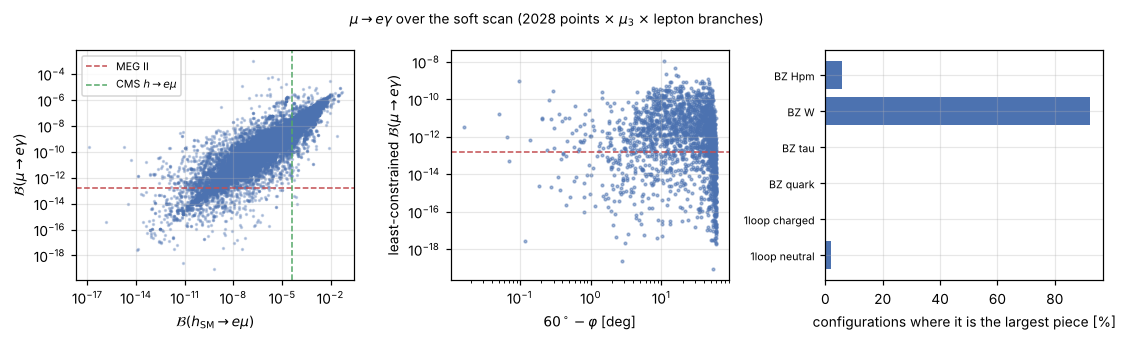

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(10.2, 3.1))
sub = np.random.default_rng(1).choice(len(br_all), min(40000, len(br_all)), replace=False)
axs[0].scatter(hemu_all[sub], br_all[sub], s=1.5, alpha=0.3, color=C_BLUE, rasterized=True)
axs[0].axhline(MEG, color=C_RED, ls="--", lw=1, label="MEG II")
axs[0].axvline(LIMIT_EMU, color=C_GREEN, ls="--", lw=1, label=r"CMS $h\to e\mu$")
axs[0].set_xscale("log"); axs[0].set_yscale("log")
axs[0].set_xlabel(r"$\mathcal{B}(h_{\rm SM}\to e\mu)$"); axs[0].set_ylabel(r"$\mathcal{B}(\mu\to e\gamma)$")
axs[0].legend(fontsize=7, loc="upper left")

axs[1].scatter(np.maximum(dphi, 1e-2), best, s=3, alpha=0.5, color=C_BLUE)
axs[1].axhline(MEG, color=C_RED, ls="--", lw=1)
axs[1].set_xscale("log"); axs[1].set_yscale("log")
axs[1].set_xlabel(r"$60^\circ-\varphi$ [deg]"); axs[1].set_ylabel(r"least-constrained $\mathcal{B}(\mu\to e\gamma)$")

labels = [k_ for k_ in S.MEG_PARTS]
shares = [100 * lead.get(k_, 0) / n_cfg for k_ in labels]
axs[2].barh(range(len(labels)), shares, color=C_BLUE)
axs[2].set_yticks(range(len(labels))); axs[2].set_yticklabels([l.replace("_", " ") for l in labels], fontsize=7)
axs[2].set_xlabel("configurations where it is the largest piece [%]")
fig.suptitle(r"$\mu\to e\gamma$ over the soft scan (" + str(len(points)) + r" points $\times$ $\mu_3$ $\times$ lepton branches)", fontsize=9)
fig.tight_layout()
plt.show()

---
## 6. Deliverable

In [ ]:
payload = {
    "description": ("B(mu -> e gamma) at the " + str(len(points)) + " soft-broken viable points of viable_points_soft.json, over "
                    "notebook 06's mu_3 grid and every lepton branch. One loop (h, A, H+- with e, mu, tau "
                    "and massless nu) plus Barr-Zee (t, b under the vacuum-direction ansatz; tau computed; "
                    "W; H+- with the h H+ H- trilinears). Per point: the least-constrained configuration and "
                    "its breakdown (|A_L|^2+|A_R|^2 of each piece alone, GeV^-4)."),
    "conventions": {"meg_ii_limit": MEG, "alpha": ALPHA, "G_F_GeV-2": G_F, "m_t_GeV": M_T,
                    "mu3_grid_GeV": [float(grid[0]), float(grid[-1]), len(grid)],
                    "quark_couplings": "y_qq(h_i) = kappa_i m_q / v, none for A (ansatz)",
                    "neglected": ["phi Z gamma Barr-Zee", "H+- W gamma Barr-Zee", "HKZ13 set C"],
                    "h_lfv_limits": LIMIT},
    "summary": {"n_configurations": int(n_cfg),
                "frac_configurations_under_meg": float(meg_ok_all.mean()),
                "frac_h_allowed_configurations_under_meg": float((meg_ok_all & h_ok_all).sum() / h_ok_all.sum()),
                "n_points_allowed_h": int(pt_h.sum()), "n_points_allowed_meg": int(pt_meg.sum()),
                "n_points_allowed_both": int(pt_both.sum()),
                "median_br": float(np.median(br_all)),
                "median_meg_over_hemu_ratio": float(np.median(ratio)),
                "largest_piece_share": {k_: lead.get(k_, 0) / n_cfg for k_ in S.MEG_PARTS},
                "n_points_allowed_meg_variants": {k_: int(v_.sum()) for k_, v_ in pt_var.items()}},
    "points": [{"point": i, "phi": points[i]["phi"], "kappa_v": float(kv[i]),
                "best": (min(rows, key=lambda x: x["br"]) if rows else None),
                "n_configurations": len(rows), "n_meg_allowed": sum(1 for x in rows if x["br"] < MEG)}
               for i, rows in enumerate(scan)],
}
def _round(o):
    "4 significant figures: the JSON is a record of the scan, not an input to anything."
    if isinstance(o, dict):
        return {k_: _round(v_) for k_, v_ in o.items()}
    if isinstance(o, (list, tuple)):
        return [_round(v_) for v_ in o]
    if isinstance(o, (float, np.floating)):
        return float("%.4g" % o)
    return o


out = store.write("mu_e_gamma", _round(payload), separators=(",", ":"), default=float)
print("wrote results/%s (%.0f kB; its points went to cache/)" % (out.name, out.stat().st_size / 1024))

wrote results/mu_e_gamma.json (2 kB; its points went to cache/)


In [ ]:
ledger.step(r"Lepton couplings of every physical scalar",
            obtained="derived",
            checks=(r"$Y^{(a_k)}=iY^{(r_k)}$, $Y^{(c_k)}=\sqrt2Y^{(r_k)}$ emerge from the Lagrangian",
                    r"Goldstone couplings flavour-diagonal at every soft vacuum",
                    r"all 7 states agree with feynlag's extractor at a non-aligned point"),
            falsified_by=r"a missing $\sqrt2$ on the charged coupling (falsify run)", section="1")
ledger.step(r"One-loop neutral dipole in closed form, exact in $m_f/m_\phi$",
            obtained="derived",
            statement=r"c_L=\sum_f\frac{\tfrac12I_1(t_f)(m_eY_{ef}Y^*_{\mu f}+m_\mu Y^*_{fe}Y_{f\mu})+I_2(t_f)m_fY^*_{fe}Y^*_{\mu f}}{4m_\mu m_\phi^2}",
            checks=(r"equals [HKZ13] (A3) with external masses kept, to $10^{-4}$, at a heavy and a light scalar",
                    r"$t\to0$ gives the [OST16]/[HKZ13] logs; [OST16] (30)'s $m_i/m_\mu$ on the non-flip term is a typo"),
            falsified_by=r"the [OST16] (30) non-flip factor (falsify run)", section="2.1")
ledger.step(r"Charged one loop $=-\tfrac12\times$ neutral non-flip",
            obtained="imported",
            checks=(r"the [Lavoura03] (40)/(41) and [OST16] (32) ratios agree independently",), section="2.2")
ledger.step(r"Barr--Zee fermion and $W$ terms",
            obtained="imported",
            checks=(r"top term = [HKZ13] (14) to 1 percent",
                    r"$W$ bracket = [Ilisie15] $F^{(3)}$ to 1 percent; [HKZ13]'s 0.11 is 14 percent lower (set C, not implemented)"),
            section="2.3 ([OST16], [HKZ13], [Ilisie15])")
ledger.step(r"Barr--Zee $H^\pm$ term and the sign $\lambda=-g/v$",
            obtained="derived",
            checks=(r"low-energy theorem: the [Ilisie15] vertices against feynlag's diphoton amplitude",),
            falsified_by=r"$\lambda=+g/v$ (falsify run)", section="2.4")
ledger.step(r"Assembly and BR normalization",
            obtained="imported",
            checks=(r"the [HKZ13] $\mu\to e\gamma$ bound is reproduced after the $W$-term rescaling",),
            falsified_by=r"a factor-2 normalization error (falsify run)", section="2.5")
ledger.step(r"$\mu\to e\gamma$ vanishes at the exact-S$_3$ vacuum (residual $\mathbb Z_2$)",
            obtained="derived",
            checks=(r"$\mathcal B<10^{-24}$ (round-off) at 40 exact points $\times$ 3 values of $\mu_3$",
                    r"$\mathcal B\propto(60^\circ-\varphi)^2$ off the alignment",
                    r"identical at the S$_3$ image (30 points, all configurations)"),
            section="3-4")
ledger.step(r"Quark couplings along the vacuum direction",
            obtained="assumed",
            checks=(r"same ansatz as notebook 06's $\kappa_t=\kappa_V$",), section="5")
ledger.table()
ledger.to_latex("derivations_07.tex", subtitle="one loop and Barr-Zee, against MEG II")

### Derivation ledger — 07 — the radiative decay of the muon in the soft-broken vacuum

**1. Lepton couplings of every physical scalar**  
<sub>derived here &nbsp;·&nbsp; §1</sub>

- ✓ $Y^{(a_k)}=iY^{(r_k)}$, $Y^{(c_k)}=\sqrt2Y^{(r_k)}$ emerge from the Lagrangian
- ✓ Goldstone couplings flavour-diagonal at every soft vacuum
- ✓ all 7 states agree with feynlag's extractor at a non-aligned point

*Would be falsified by:* a missing $\sqrt2$ on the charged coupling (falsify run)


---

**2. One-loop neutral dipole in closed form, exact in $m_f/m_\phi$**  
<sub>derived here &nbsp;·&nbsp; §2.1</sub>

$$c_L=\sum_f\frac{\tfrac12I_1(t_f)(m_eY_{ef}Y^*_{\mu f}+m_\mu Y^*_{fe}Y_{f\mu})+I_2(t_f)m_fY^*_{fe}Y^*_{\mu f}}{4m_\mu m_\phi^2}$$

- ✓ equals [HKZ13] (A3) with external masses kept, to $10^{-4}$, at a heavy and a light scalar
- ✓ $t\to0$ gives the [OST16]/[HKZ13] logs; [OST16] (30)'s $m_i/m_\mu$ on the non-flip term is a typo

*Would be falsified by:* the [OST16] (30) non-flip factor (falsify run)


---

**3. Charged one loop $=-\tfrac12\times$ neutral non-flip**  
<sub>**imported** &nbsp;·&nbsp; §2.2</sub>

- ✓ the [Lavoura03] (40)/(41) and [OST16] (32) ratios agree independently

---

**4. Barr--Zee fermion and $W$ terms**  
<sub>**imported** &nbsp;·&nbsp; §2.3 ([OST16], [HKZ13], [Ilisie15])</sub>

- ✓ top term = [HKZ13] (14) to 1 percent
- ✓ $W$ bracket = [Ilisie15] $F^{(3)}$ to 1 percent; [HKZ13]'s 0.11 is 14 percent lower (set C, not implemented)

---

**5. Barr--Zee $H^\pm$ term and the sign $\lambda=-g/v$**  
<sub>derived here &nbsp;·&nbsp; §2.4</sub>

- ✓ low-energy theorem: the [Ilisie15] vertices against feynlag's diphoton amplitude

*Would be falsified by:* $\lambda=+g/v$ (falsify run)


---

**6. Assembly and BR normalization**  
<sub>**imported** &nbsp;·&nbsp; §2.5</sub>

- ✓ the [HKZ13] $\mu\to e\gamma$ bound is reproduced after the $W$-term rescaling

*Would be falsified by:* a factor-2 normalization error (falsify run)


---

**7. $\mu\to e\gamma$ vanishes at the exact-S$_3$ vacuum (residual $\mathbb Z_2$)**  
<sub>derived here &nbsp;·&nbsp; §3-4</sub>

- ✓ $\mathcal B<10^{-24}$ (round-off) at 40 exact points $\times$ 3 values of $\mu_3$
- ✓ $\mathcal B\propto(60^\circ-\varphi)^2$ off the alignment
- ✓ identical at the S$_3$ image (30 points, all configurations)

---

**8. Quark couplings along the vacuum direction**  
<sub>**assumed** &nbsp;·&nbsp; §5</sub>

- ✓ same ansatz as notebook 06's $\kappa_t=\kappa_V$

---

<sub>8 steps: 4 derived here, 3 imported, 1 assumed</sub>

wrote derivations_07.tex  (8 steps)


'derivations_07.tex'

---
## 7. Findings

1. **Every scalar's lepton couplings come off the Lagrangian and agree with the extractor**
   (§1). The doublet structure gives $Y^{(a_k)}=iY^{(r_k)}$ and $Y^{(c_k)}=\sqrt2\,Y^{(r_k)}$.
   The Goldstones are flavour-diagonal at every soft vacuum. At a non-aligned point all
   seven physical scalars' matrices match feynlag's `extract_fermion_vertices` to
   $10^{-18}$. μ→eγ also needs the **signs** of the lepton eigenvalues, which h→ℓℓ′ never
   did. `lfv.signed_mass_basis` keeps them and rephases $e_R$.

2. **The amplitude is checked piece by piece against independent sources** (§2).
   - The one-loop closed form, exact in $m_f/m_\phi$, equals [HKZ13] Eq. (A3) with the
     external masses kept.
   - [OST16] Eq. (30) has a typo: it attaches $m_i/m_\mu$ to the non-flip term.
   - The charged loop is $-\tfrac12$ the neutral non-flip loop, from [Lavoura03] and [OST16]
     independently.
   - The top Barr–Zee term reproduces [HKZ13] to 1%. The $W$ bracket agrees with
     [Ilisie15]'s independent $F^{(3)}$ to 1% but sits 14% above [HKZ13]'s quoted 0.11,
     most likely their "set C", which is not implemented here.
   - The $H^\pm$ Barr–Zee term is new here, and its sign ($\lambda=-g/v$) is fixed by the
     low-energy theorem against feynlag's diphoton amplitude.
   - The assembled rate reproduces [HKZ13]'s bound after the $W$ rescaling. With MEG II, an
     SM-like Higgs needs $\sqrt{|Y_{\mu e}|^2+|Y_{e\mu}|^2}<7.2\times10^{-7}$.

3. **μ→eγ vanishes identically at the exact-S₃ vacuum** (§3), although $h_0$, one $A$ and
   one $H^\pm$ carry $e\mu$ couplings up to $\sim0.1$. The residual $\mathbb Z_2$ of the
   aligned vacuum makes the electron and those scalars odd, and the dipole is then forbidden
   to all orders. So μ→eγ **measures the soft breaking directly**. Moving one exact point off
   the alignment with no free soft terms, $\mathcal B\propto(60^\circ-\varphi)^2$, and
   $0.1^\circ$ already gives $1.9\times10^{-13}$, at the MEG II limit. This is the
   radiative-decay face of the first-generation decoupling that also forces $V_{us}=0$
   (`NOTES.md` findings 9–10).

4. **In the soft vacuum μ→eγ is the binding LFV constraint, by orders of magnitude** (§5).
   Over 417 992 (point, $\mu_3$, branch) configurations the median is
   $\mathcal B=7.6\times10^{-10}$. Only 2.51% of configurations pass MEG II, against 79.8%
   for the three Higgs LFV limits. Measured against its own limit, μ→eγ is a median
   $9.1\times10^4$ times more restrictive than $h\to e\mu$ in the same configuration.
   **618 of 2028 scalar points** keep a MEG-allowed lepton configuration, 606 once the
   $h\to\ell\ell'$ limits are imposed as well. The $h\to\ell\ell'$ limits alone keep 2023
   (notebook 06). So μ→eγ, unlike every Higgs LFV decay, **does constrain the scalar
   sector**: it removes about 70% of it.

5. **The $W$-loop Barr–Zee diagram through the SM-like Higgs dominates.** It is the largest
   piece in 92% of configurations, the $H^\pm$ Barr–Zee term in 5.8%, and the one loop
   almost never. The SM-like state's $e\mu$ coupling is pure non-vacuum admixture (`NOTES.md`
   finding 12; notebook 06 §5), so survivors are more aligned: their median $1-\kappa_V^2$ is $8.3\times10^{-4}$,
   against $2.4\times10^{-3}$ overall. No $\mu_3$ window or lepton-branch kind is singled
   out: MEG-allowed configurations span the whole $|\mu_3|$ axis and all three kinds.
   Proximity to $\varphi=\pi/3$ alone does not protect a point. In the scan the free soft
   terms break the $\mathbb Z_2$ whatever φ is, so φ is not its order parameter.

6. **The conclusion survives the two weak spots of the amplitude.** Dropping the quark
   Barr–Zee ansatz, flipping its sign, or scaling the $W$ loop to [HKZ13]'s number leaves
   504, 453 and 684 surviving points respectively, against 618. The quark sector moves
   the count by about 25% and does not change the conclusion.

## Open questions

- **[HKZ13]'s "set C"** and the $\phi Z\gamma$ (+6% on the $W$ term) and $H^\pm W^\mp\gamma$
  Barr–Zee diagrams are not included. The variants above bound their likely effect on the
  point count, but not exactly.
- **The quark sector per point.** The Barr–Zee quark loops are an ansatz, as notebook 06's
  $\kappa_t$ is.
- **An order parameter for the residual $\mathbb Z_2$** in the soft vacuum (a combination of
  soft terms, not φ), to turn finding 5's last remark into a scan variable.
- **μ→3e and μ–e conversion** share this dipole and add contact terms. **τ→μγ, τ→eγ** need
  only the indices of `radiative.py` generalized.

In [ ]:
check_quoted("7", [
    ("SM-like MEG II bound /1e-7", meg_bound / 1e-7, 7.2, 0.05),
    ("B at 0.1 deg /1e-13", br_list[2] / 1e-13, 1.9, 0.05),
    ("configurations", n_cfg, 417992, 0),
    ("median B /1e-10", np.median(br_all) / 1e-10, 7.6, 0.05),
    ("% configurations under MEG", 100 * meg_ok_all.mean(), 2.51, 0.005),
    ("% configurations under the h limits", 100 * h_ok_all.mean(), 79.8, 0.05),
    ("median restrictiveness ratio /1e4", np.median(ratio) / 1e4, 9.1, 0.05),
    ("points allowed by MEG", pt_meg.sum(), 618, 0),
    ("points allowed by both", pt_both.sum(), 606, 0),
    ("points allowed by the h limits", pt_h.sum(), 2023, 0),
    ("% BZ_W largest", 100 * lead["BZ_W"] / n_cfg, 92, 0.5),
    ("% BZ_Hpm largest", 100 * lead["BZ_Hpm"] / n_cfg, 5.8, 0.05),
    ("survivors' median 1-kappa^2 /1e-4", np.median(1 - kv[pt_meg] ** 2) / 1e-4, 8.3, 0.05),
    ("all points' median 1-kappa^2 /1e-3", np.median(1 - kv**2) / 1e-3, 2.4, 0.05),
    ("variant no_quark", pt_var["no_quark"].sum(), 504, 0),
    ("variant top_flip", pt_var["top_flip"].sum(), 453, 0),
    ("variant w_hkz", pt_var["w_hkz"].sum(), 684, 0),
])

✓ the 17 numbers quoted in §7 match this run


---
## 8. References

- **[OST16]** Y. Omura, E. Senaha, K. Tobe, *"τ- and μ-physics in a general two Higgs doublet
  model with μ−τ flavor violation"*, Phys. Rev. D **94**, 055019 (2016),
  [arXiv:1511.08880](https://arxiv.org/abs/1511.08880). Eqs. (6)–(7) the Yukawa convention,
  (16)–(21) the τ→μγ amplitude and Barr–Zee terms, (28)–(33) μ→eγ.
- **[HKZ13]** R. Harnik, J. Kopp, J. Zupan, *"Flavor violating Higgs decays"*,
  JHEP **03** (2013) 026, [arXiv:1209.1397](https://arxiv.org/abs/1209.1397). Eq. (A3) the
  exact one-loop integral, Eqs. (A4)–(A9) Barr–Zee, Eqs. (14)–(15) and Table I the numerical
  oracles.
- **[Ilisie15]** V. Ilisie, *"New Barr-Zee contributions to (g−2)_μ in two-Higgs-doublet
  models"*, JHEP **04** (2015) 077, [arXiv:1502.04199](https://arxiv.org/abs/1502.04199).
  Eqs. (11), (13) the φγγ vertices with an off-shell photon; Eq. (28) the $W$-loop function.
- **[Lavoura03]** L. Lavoura, *"General formulae for f₁ → f₂γ"*, Eur. Phys. J. C **29**, 191
  (2003), [hep-ph/0302221](https://arxiv.org/abs/hep-ph/0302221). Eqs. (40)–(41).
- **[MEGII25]** MEG II Collaboration, *"New limit on the μ⁺→e⁺γ decay with the MEG II
  experiment"* (2025), [arXiv:2504.15711](https://arxiv.org/abs/2504.15711).
  $\mathcal B<1.5\times10^{-13}$ at 90% CL.
- **[CMS21]**, **[CMS23]** the Higgs LFV limits, as in notebook 06 and `decays.LFV_LIMITS`.
- **[ChakrabartyEtAl21]** the charged-scalar diphoton normalization, via
  `feynlag.pheno.loop`.
- **[PDG]** S. Navas *et al.*, Phys. Rev. D **110**, 030001 (2024): $G_F$, α and the masses
  in `sm_inputs.py`.